In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
from tqdm.notebook import tqdm
from collections import defaultdict
from scipy.spatial import ConvexHull
import plotly.express as px

### Подготовим данные о НК и НЧ

In [2]:
def get_min_distance_to_hull(positions:np.ndarray):
    """
    Находит минимальное расстояние от поглощающего атома внутри ConvexHull до его поверхности.
    """
    p = np.array([0,0,0])
    hull = ConvexHull(positions)
    A_B_C = hull.equations[:, :-1]  # Матрица нормалей (N, 3)
    D = hull.equations[:, -1]       # Вектор сдвигов (N,)
    distances = np.abs(np.dot(A_B_C, p) + D)
    return np.min(distances).round(4)

In [3]:
unique_substructures_df = pd.read_pickle('../source_data/INIT_unique_substructures_Rcut_7.5_stephist_0.1.pkl')
unique_substructures_df['size'] =  unique_substructures_df['Structure'].apply(lambda x: x.get_all_distances().max().round(4))
unique_substructures_df['surface_proximity'] =  unique_substructures_df['Structure'].apply(lambda x: get_min_distance_to_hull(x.positions))
unique_substructures_df['surface_proximity_normed'] = unique_substructures_df['surface_proximity']/unique_substructures_df['size']

In [4]:
NP_BASIS = pd.read_pickle('../source_data/NP_basis_representation_from_substructures.pkl')
NP_BASIS = NP_BASIS.sort_values(by='NP_index', ascending=True) # Убедимся что датафрейм отсортирован

NP_INFO = pd.read_pickle('../processed_data/NP_info.pkl')
NP_INFO = NP_INFO[['NP_index','shape','n_atoms','Pair_init_size','Equil_CN1','Equil_CN2','Equil_CN3']]
NP_INFO['NP_index'] = NP_INFO['NP_index'].astype(int)
NP_DATA = NP_BASIS.merge(NP_INFO, how='left', left_on='NP_index', right_on='NP_index')

In [5]:
records = []
CN_ALL_SUB = np.array(unique_substructures_df.CN.values.tolist())

for _, row_NP in tqdm(NP_DATA.iterrows(), total=NP_DATA.shape[0]):

    weights_normed = row_NP['Weighted_vector']/row_NP['Weighted_vector'].sum()
    weights_mask = weights_normed>0    
    weights_masked = weights_normed[weights_mask]
    sub_df = unique_substructures_df[weights_mask]

    NP_CN = (weights_normed@CN_ALL_SUB).round(2)
    
    NP_info = {'NP_index': row_NP['NP_index'],
               'NP_shape': row_NP['shape'],
               'NP_N_atoms': row_NP['n_atoms'],
               'NP_size': np.round(row_NP['Pair_init_size'],2),
               'NP_CN': NP_CN,
               'Eq_CN1': row_NP['Equil_CN1'],
               'Eq_CN2': row_NP['Equil_CN2'],
               'Eq_CN3': row_NP['Equil_CN3'],
              }
    
    for w, (_, row_sub) in zip(weights_masked, sub_df.iterrows()):
        record = {**NP_info,
                  'NC_N_atoms': row_sub['Num_atoms'],
                  'NC_size': np.round(row_sub['size'], 2),
                  'NC_surface_proximity_normed': row_sub['surface_proximity_normed'],
                  'NC_weight': w,
                  'NC_CN': row_sub['CN'],
                 }
        records.append(record)

pivot_df = pd.DataFrame(records)

  0%|          | 0/800 [00:00<?, ?it/s]

In [6]:
pivot_df.loc[[0,100,400]]

,NP_index,NP_shape,NP_N_atoms,NP_size,NP_CN,Eq_CN1,Eq_CN2,Eq_CN3,NC_N_atoms,NC_size,NC_surface_proximity_normed,NC_weight,NC_CN
0,1,sph,141,15.60,"[8.85, 3.91, 13.62, 5.87, 10.89, 3.18, 17.02]",9.42,3.80,13.85,46,12.33,0.000000,0.042553,"[4.0, 1.0, 12.0, 4.0, 4.0, 4.0, 16.0]"
100,4,sph,683,27.02,"[10.19, 4.73, 17.57, 8.45, 15.88, 5.04, 28.95]",10.19,5.59,18.18,127,14.59,0.367881,0.070278,"[12.0, 6.0, 24.0, 12.0, 24.0, 7.0, 41.0]"
400,10,sph,4585,50.55,"[11.02, 5.32, 20.59, 10.04, 19.64, 6.39, 37.67]",10.11,4.96,20.20,75,14.33,0.045361,0.010469,"[9.0, 3.0, 13.0, 7.0, 14.0, 4.0, 24.0]"


### Подготовка спектров

In [7]:
SPECTRA_ROOT = Path('../processed_data/conv_dense_spectra/')
SPECTRA_PATH_LIST = sorted(list(SPECTRA_ROOT.iterdir()), key=lambda x: int(x.name.split('.')[0]))

In [8]:
E_min_norm, E_max_norm = 25, 40

In [9]:
# Мы знаем что все размазанные спектры имеют общую шкалу энергий, сохраним ее и определим маску для нормировки
theory_E_array = np.loadtxt(SPECTRA_PATH_LIST[0])[:,0]
theory_mask = (theory_E_array>E_min_norm)&(theory_E_array<E_max_norm)

In [10]:
%%time
# Кэшируем спектры нормированные спектры
normded_spectra_y_cache = {}
for path in tqdm(SPECTRA_PATH_LIST):
    ind = int(path.name.split('.')[0])
    spectra_y = np.loadtxt(SPECTRA_PATH_LIST[ind])[:,1]
    spectra_y = spectra_y/(spectra_y[theory_mask].max())
    normded_spectra_y_cache[ind]=spectra_y

  0%|          | 0/2151 [00:00<?, ?it/s]

CPU times: total: 8.52 s
Wall time: 8.44 s


In [11]:
# Загружаем экспериментальный спектр фольги
foil_spectrum_exp = np.loadtxt('../source_data/PtL3_foil.txt')
# Выравнивание эксперимента по краю поглощения (максимум производной)
d_exp = (foil_spectrum_exp[1:, 1] - foil_spectrum_exp[:-1, 1]) / (foil_spectrum_exp[1:, 0] - foil_spectrum_exp[:-1, 0])
# Находим индекс максимального наклона и соответствующую энергию края
E_edge_exp = foil_spectrum_exp[np.argmax(d_exp), 0]

# Переводим экспериментальную сетку в относительную шкалу (E - E_edge)
exp_x = foil_spectrum_exp[:, 0] - E_edge_exp

# Интерполируем эксперимент в сетку теории
exp_y = np.interp(theory_E_array,exp_x,foil_spectrum_exp[:, 1])
exp_y_normed = exp_y/(exp_y[theory_mask].max())

EXPERIMENT = np.column_stack((theory_E_array,exp_y_normed))

In [12]:
SPECTRA_Y = np.array(list(normded_spectra_y_cache.values()))

In [13]:
NP_spectra_cache = {}
for ind in tqdm(NP_BASIS.index.tolist()):
    NP_ind = NP_BASIS.NP_index.loc[ind]
    weights = NP_BASIS.Weighted_vector.loc[ind]
    weights = weights/weights.sum()
    NP_spectrum = weights@SPECTRA_Y
    NP_spectra_cache[int(NP_ind)] = NP_spectrum

  0%|          | 0/800 [00:00<?, ?it/s]

In [14]:
NP_DATA.head()

,NP_index,Weighted_vector,shape,n_atoms,Pair_init_size,Equil_CN1,Equil_CN2,Equil_CN3
0,1,"[0.0, 0.0, 0.0, 0.0, 0.0, 6.0, 0.0, 0.0, 0.0, ...",sph,141,15.6000,9.42,3.80,13.85
1,2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",sph,249,19.1060,10.69,4.56,15.08
2,3,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",sph,453,23.5386,9.83,4.61,16.97
3,4,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",sph,683,27.0200,10.19,5.59,18.18
4,5,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",sph,1061,31.2000,10.38,4.85,18.54


## Посмотрим на значения MSE спектров НЧ и эксп. фольги в зависимости от кол-ва атомов и размеров НЧ.

In [15]:
NP_spectra_y = np.array(list(NP_spectra_cache.values()))
NP_size = NP_DATA.Pair_init_size.values.round(2)
NP_N_atoms = NP_DATA.n_atoms.values
MSE = (((NP_spectra_y-EXPERIMENT[:,1])**2).sum(axis=1))/theory_E_array.shape[0]

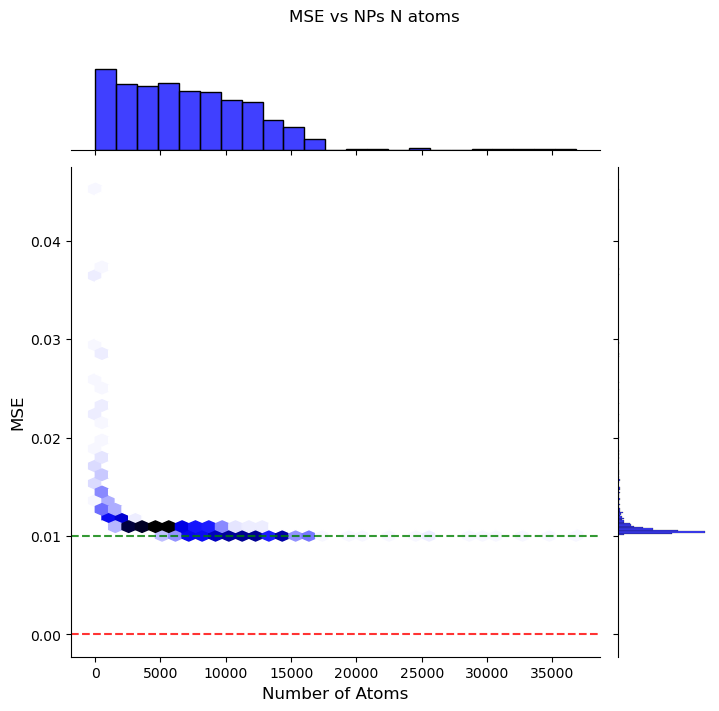

In [16]:
g = sns.jointplot(x=NP_N_atoms, y=MSE, kind="hex", color="blue", height=7) # #4CB391
g.set_axis_labels('Number of Atoms', 'MSE', fontsize=12)
g.ax_joint.axhline(0, color='red', linestyle='--', linewidth=1.5, alpha=0.8)
g.ax_joint.axhline(0.01, color='green', linestyle='--', linewidth=1.5, alpha=0.8)

plt.subplots_adjust(top=0.9)
g.fig.suptitle('MSE vs NPs N atoms')
plt.savefig("../images/MSE_vs_NP_N_atoms", dpi=600)
plt.show()

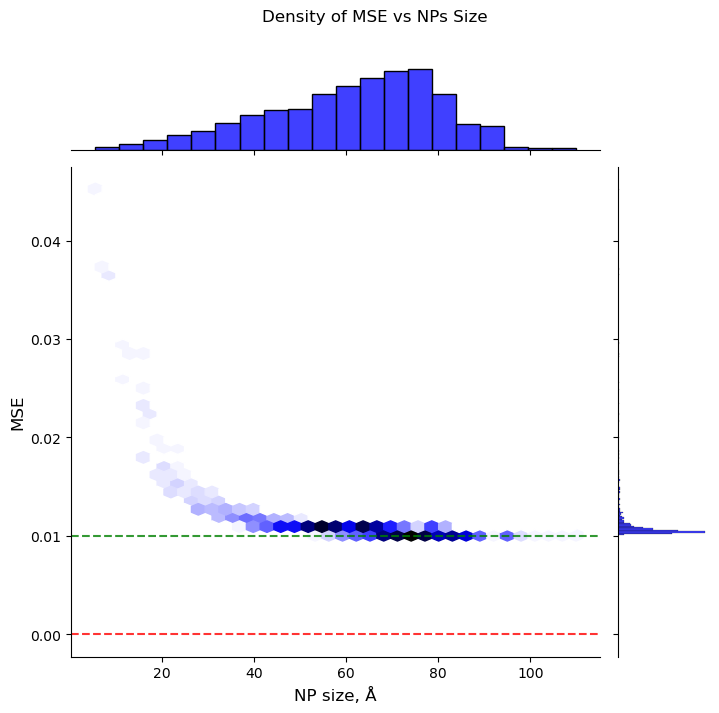

In [17]:
g = sns.jointplot(x=NP_size, y=MSE, kind="hex", color="blue", height=7) # #4CB391
g.set_axis_labels('NP size, Å', 'MSE', fontsize=12)
g.ax_joint.axhline(0, color='red', linestyle='--', linewidth=1.5, alpha=0.8)
g.ax_joint.axhline(0.01, color='green', linestyle='--', linewidth=1.5, alpha=0.8)

# sline = lambda x: 0.07*np.exp(-0.1*x) + 0.01
# plt.scatter(NP_size, sline(NP_size), color='black', marker='o', s=0.2)

plt.subplots_adjust(top=0.9)
g.fig.suptitle('Density of MSE vs NPs Size')
plt.savefig("../images/Density_of_MSE_vs_NP_Size", dpi=600)
plt.show()

In [18]:
# Из графиков видно, что изменение MSE от размера или кол-ва атомов в НЧ ведет себя экспоненциально
# и в целом демонстрирует ожидаемую тенденцию приближения к эксп. фольге с ростом размеров НЧ.

## Посмотрим на зависимость составов НЧ в контексте размеров, кол-ва атомов, и близости к поверхности входящих в ее состав НК.

In [19]:
fig = px.scatter(pivot_df, 
                 x="NP_N_atoms", 
                 y="NC_N_atoms", 
                 size="NC_weight", 
                 color="NC_weight",
                 hover_data=['NP_N_atoms', 'NC_N_atoms', 'NC_weight'],
                 title="Вклады подструктур (размер пузырька = NC_weight)",
                 labels={'NP_N_atoms': 'Кол-во атомов в НЧ', 'NC_N_atoms': 'Кол-во атомов в подструктурах'},
                 template='plotly_white')

fig.write_image("../images/NP_compositions_by_NC_N_atoms.png", scale=2)

fig.show()

In [20]:
fig = px.scatter(pivot_df, 
                 x="NP_size", 
                 y="NC_size", 
                 size="NC_weight", 
                 color="NC_weight",
                 hover_data=['NP_size', 'NC_size', 'NC_weight'],
                 title="Вклады подструктур (размер пузырька = NC_weight)",
                 labels={'NP_size': 'Размер НЧ, Å', 'NC_size, Å': 'Размер подструктурах'},
                 template='plotly_white')

fig.write_image("../images/NP_compositions_by_NC_size.png", scale=2)

fig.show()

In [21]:
fig = px.scatter(pivot_df, 
                 x="NP_size", 
                 y="NC_surface_proximity_normed", 
                 size="NC_weight", 
                 color="NC_weight",
                 hover_data=['NP_size', 'NC_surface_proximity_normed', 'NC_weight'],
                 title="Вклады подструктур (размер пузырька = NC_weight)",
                 labels={'NP_size': 'Размер НЧ, Å', 'NC_surface_proximity_normed': 'Расстояние подструктур до поверхности'},
                 template='plotly_white')

fig.write_image("../images/NP_compositions_by_NC_surf_proximity.png", scale=2)

fig.show()

In [22]:
# Представленные графики "компонентного" состава НЧ также демонстрируют ожидаемое поведение,
# что свидетельствует о корректности/отсутствии значительных неточностей в данных.

## Как и для НК посмотрим на корреляции точек спектра НЧ с набором первых 4 КЧ.

In [23]:
cutted_df = pivot_df.drop_duplicates('NP_index')
CN_all = np.array(cutted_df.NP_CN.values.tolist())

EQ_CN1 = cutted_df.Eq_CN1.values
EQ_CN2 = cutted_df.Eq_CN2.values
EQ_CN3 = cutted_df.Eq_CN3.values

CN1 = CN_all[:,0]
CN2 = CN_all[:,1]
CN3 = CN_all[:,2]
CN4 = CN_all[:,3]

In [24]:
# Проинтерполируем наши спектры в новую более "редкую" сетку энергий.
E_new = np.arange(-10,60.5,1)
spectras_y_interp = np.array(list(map(lambda x: np.interp(E_new,theory_E_array,x).tolist(),NP_spectra_y)))
# создадим словарь с необходимыми данными
data_corr = {'EQ_CN1':EQ_CN1, 
             'EQ_CN2':EQ_CN2, 
             'EQ_CN3':EQ_CN3,
             'CN1':CN1, 
             'CN2':CN2, 
             'CN3':CN3, 
             'CN4':CN4}
for ind in range(spectras_y_interp.shape[1]):
    data_corr[-10+ind] = spectras_y_interp[:,ind]

corr_df = pd.DataFrame(data_corr)

corr_df = corr_df.corr().loc[['EQ_CN1','EQ_CN2','EQ_CN3','CN1','CN2','CN3','CN4']].drop(columns=['EQ_CN1','EQ_CN2','EQ_CN3','CN1','CN2','CN3','CN4'])
corr_df = abs(corr_df)

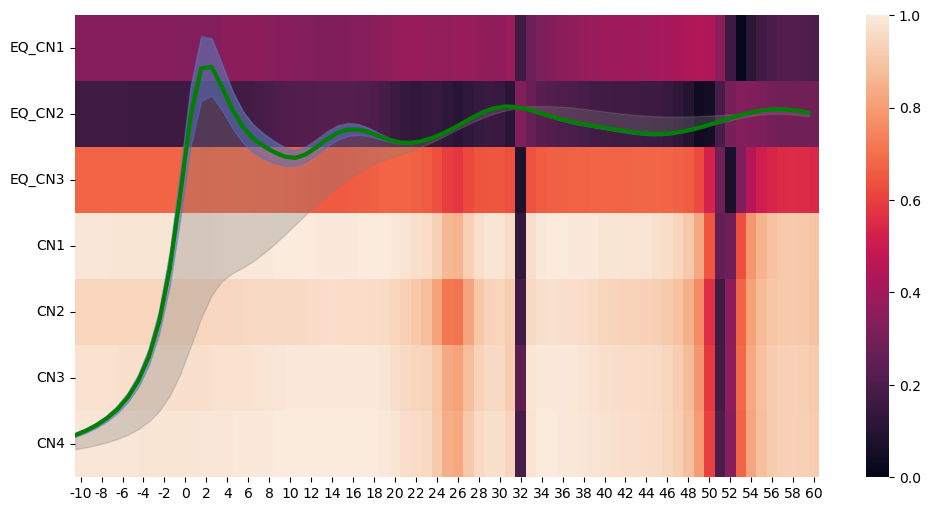

In [25]:
mean_y = np.mean(spectras_y_interp, axis=0)

std_y = np.std(spectras_y_interp, axis=0)

min_y = np.min(spectras_y_interp, axis=0)
max_y = np.max(spectras_y_interp, axis=0)

lower_bound = mean_y - std_y
upper_bound = mean_y + std_y

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(corr_df,vmin=0,vmax=1,ax=ax)
spectra_cor = lambda x: (1.25-x)*5.5
ax.plot(spectra_cor(mean_y), color='green', ls='-', lw=3)
ax.fill_between(np.arange(0,71),spectra_cor(upper_bound), spectra_cor(lower_bound), color='royalblue', alpha=0.5, label='Std')
ax.fill_between(np.arange(0,71),spectra_cor(min_y), spectra_cor(max_y), color='gray', alpha=0.3, label='Std')
plt.yticks(rotation=0)

plt.savefig('../images/XANES_NP_corr_CN.png', dpi=600)

plt.show()

In [26]:
# Из графика видно, что спектры НЧ показывают хорошую корреляцию с КЧ для не оптимизированных структур.
# Затемненные полосы на графике очевидно связаны с областями наименьших относительных изменений в спектре
# (самая темная полоса на 32 eV - область нормировки спектров).
# Также видно, что для КЧ расчитанных для НЧ приведенных в равновесие с термостатом корреляция заметно хуже,
# что скорее всего обусловлено несоответствиями со спектрами не оптимизированных НЧ.